# Lab 04-11 · Introduction to Solid-State Physics

Companion to chapter [04-11](../../chapters/04-11-intro-solid-state-physics.md). Handout: [README.md](README.md).

Cells marked **🔮 Predict** ask for a prediction *before* running. Nothing here is random, so every number reproduces exactly.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
h, e, me, kB = 6.62607015e-34, 1.602176634e-19, 9.1093837139e-31, 1.380649e-23
hbar = h / (2 * math.pi)

## Part 1 — Fill the box

In a periodic box of side $L$ the allowed wavevectors are $\vec k = (2\pi/L)(n_x, n_y, n_z)$ with integer $n$'s, and the energy is $E = (\hbar^2/2m)(2\pi/L)^2\,|\vec n|^2$. Measuring energy in units of $(\hbar^2/2m)(2\pi/L)^2$, a state's energy is just $|\vec n|^2$, and the chapter's formula predicts the top filled level for $N$ electrons at $E_F = (3N/8\pi)^{2/3}$ in the same units.

**🔮 Predict:** how many electrons must the box hold before the counted Fermi level agrees with the formula to 1%?

In [2]:
nmax = 40
r = np.arange(-nmax, nmax + 1)
n2 = (r[:, None, None]**2 + r[None, :, None]**2 + r[None, None, :]**2).ravel()
n2.sort()                                    # each entry is one k-state; two electrons per state
for N in (10, 100, 1000, 10_000, 100_000):
    top = n2[N // 2 - 1]                     # energy of the highest filled state
    formula = (3 * N / (8 * math.pi)) ** (2 / 3)
    print(f"N = {N:>7}: counted E_F = {top:5d}, formula = {formula:9.2f}, ratio = {top / formula:.4f}")

N =      10: counted E_F =     1, formula =      1.13, ratio = 0.8887
N =     100: counted E_F =     5, formula =      5.22, ratio = 0.9573
N =    1000: counted E_F =    25, formula =     24.24, ratio = 1.0312
N =   10000: counted E_F =   113, formula =    112.53, ratio = 1.0042
N =  100000: counted E_F =   522, formula =    522.30, ratio = 0.9994


The counted level jumps in steps (many $\vec n$ share the same $|\vec n|^2$, like electron shells), so the ratio wobbles, but it converges: by $10^4$ electrons it is within 0.5%, and by $10^5$ within 0.1%. A real sample has $10^{22}$ or more, so the formula is exact for practical purposes. The leftover error is the surface of the sphere, a fraction of order $1/(k_FL)$.

## Part 2 — Sommerfeld's heat capacity, numerically

Take the free-electron density of states $g(E)\propto\sqrt E$ with $E_F = 1$ (so energies and $kT$ are in units of $E_F$, and $kT$ is $T/T_F$). At each temperature, find the chemical potential μ that keeps the electron number fixed, compute the total energy $U(T)$, and differentiate.

**🔮 Predict:** at $T/T_F = 0.01$, what is the heat capacity per electron in units of $k$: about 1.5 (classical) or much less?

In [3]:
def mu_of(t):
    N = lambda mu: quad(lambda E: np.sqrt(E) / (1 + np.exp((E - mu) / t)), 0, mu + 40 * t, limit=200)[0] - 2 / 3
    return brentq(N, 0.5, 1.5)

def energy(t):
    mu = mu_of(t)
    return quad(lambda E: E**1.5 / (1 + np.exp((E - mu) / t)), 0, mu + 40 * t, limit=200)[0] / (2 / 3)   # per electron

for t in (0.005, 0.01, 0.02, 0.05):
    dt = 1e-4 * t
    C = (energy(t + dt) - energy(t - dt)) / (2 * dt)
    print(f"T/T_F = {t:5.3f}: mu = {mu_of(t):.6f} E_F, C per electron = {C:.5f} k, Sommerfeld (pi^2/2) T/T_F = {math.pi**2 / 2 * t:.5f} k")

T/T_F = 0.005: mu = 0.999979 E_F, C per electron = 0.02467 k, Sommerfeld (pi^2/2) T/T_F = 0.02467 k
T/T_F = 0.010: mu = 0.999918 E_F, C per electron = 0.04933 k, Sommerfeld (pi^2/2) T/T_F = 0.04935 k
T/T_F = 0.020: mu = 0.999671 E_F, C per electron = 0.09858 k, Sommerfeld (pi^2/2) T/T_F = 0.09870 k
T/T_F = 0.050: mu = 0.997936 E_F, C per electron = 0.24487 k, Sommerfeld (pi^2/2) T/T_F = 0.24674 k


The numerical heat capacity matches $(\pi^2/2)(T/T_F)$ closely (0.04933 against 0.04935 at $T/T_F$ = 0.01), about 3% of the classical 1.5 at that temperature, and the chemical potential barely moves: $\mu = E_F[1 - (\pi^2/12)(T/T_F)^2]$. For copper at 300 K, $T/T_F \approx 0.0037$.

## Part 3 — Bands from atoms

Diagonalize the tight-binding matrix ($E_0 = 0$ on the diagonal, $-t$ between neighbors) for chains of growing length.

**🔮 Predict:** what is the band width of a 100-atom open chain with $t$ = 1 eV: exactly 4 eV, slightly less, or slightly more?

N =    2: lowest -1.00000 eV, highest +1.00000 eV, width 2.00000 eV
N =    3: lowest -1.41421 eV, highest +1.41421 eV, width 2.82843 eV
N =   10: lowest -1.91899 eV, highest +1.91899 eV, width 3.83797 eV
N =  100: lowest -1.99903 eV, highest +1.99903 eV, width 3.99807 eV
N = 1000: lowest -1.99999 eV, highest +1.99999 eV, width 3.99998 eV
m* from the fitted curvature: 0.6096 m0;  formula hbar^2/(2 t a^2): 0.6096 m0


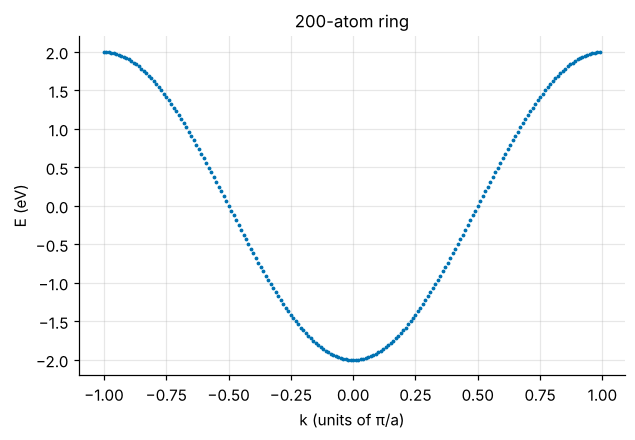

In [4]:
t = 1.0
for N in (2, 3, 10, 100, 1000):
    H = -t * (np.eye(N, k=1) + np.eye(N, k=-1))
    E = np.linalg.eigvalsh(H)
    print(f"N = {N:>4}: lowest {E[0]:+.5f} eV, highest {E[-1]:+.5f} eV, width {E[-1] - E[0]:.5f} eV")
# effective mass from a ring of 200 atoms, a = 0.25 nm
N, a = 200, 0.25e-9
k = 2 * np.pi * np.arange(N) / (N * a); k[k > np.pi / a] -= 2 * np.pi / a
E = -2 * t * np.cos(k * a)
sel = np.abs(k) < 0.08 * np.pi / a
c = np.polyfit(k[sel], E[sel] * e, 4)[2]          # E ≈ c0 + c k² + c4 k⁴: keep the k² coefficient
mstar = hbar**2 / (2 * c)
print(f"m* from the fitted curvature: {mstar / me:.4f} m0;  formula hbar^2/(2 t a^2): {hbar**2 / (2 * t * e * a**2) / me:.4f} m0")
plt.plot(k * a / np.pi, E, ".", ms=3); plt.xlabel("k (units of π/a)"); plt.ylabel("E (eV)"); plt.title("200-atom ring"); plt.show()

An open chain's width is $4t\cos(\pi/(N+1))$, slightly less than $4t$ (3.998 eV for $N$ = 100), approaching $4t$ as $N$ grows. The curvature fit recovers $m^* = \hbar^2/(2ta^2)$ = 0.6096 $m_0$ (Example 04-11.4).

## Part 4 — Bands from Bragg reflection

Write the electron's wavefunction as a sum of plane waves $e^{i(k + G)x}$ with $G = 2\pi m/a$. A potential $V(x) = 2U\cos(2\pi x/a)$ couples each plane wave to its neighbors $G \pm 2\pi/a$ with strength $U$, giving a tridiagonal matrix whose eigenvalues are the band energies at that $k$.

**🔮 Predict:** for $a$ = 0.5 nm, is the exact gap at $k = \pi/a$ larger or smaller than $2U$ when $U$ = 0.5 eV, and by how much?

U = 0.05 eV: gap at pi/a = 0.1000 eV (2U = 0.10); lower edge 1.4539 eV
U = 0.20 eV: gap at pi/a = 0.3999 eV (2U = 0.40); lower edge 1.3009 eV
U = 0.50 eV: gap at pi/a = 0.9983 eV (2U = 1.00); lower edge 0.9842 eV
U = 1.00 eV: gap at pi/a = 1.9863 eV (2U = 2.00); lower edge 0.4277 eV


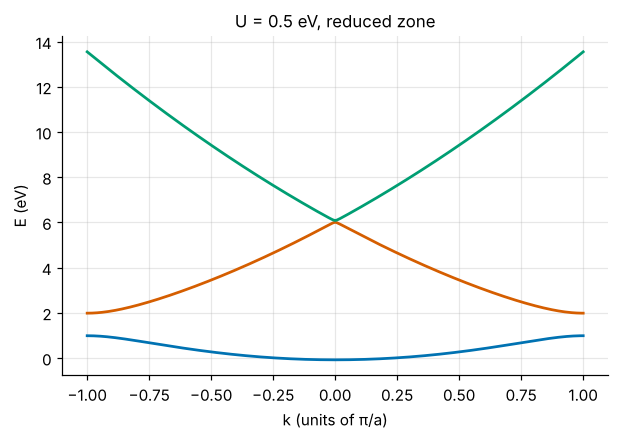

In [5]:
def bands(k, a, U, nG=31):
    G = 2 * np.pi / a * np.arange(-(nG // 2), nG // 2 + 1)
    H = np.diag(hbar**2 * (k + G)**2 / (2 * me) / e) + U * (np.eye(nG, k=1) + np.eye(nG, k=-1))
    return np.linalg.eigvalsh(H)

a = 0.5e-9
for U in (0.05, 0.2, 0.5, 1.0):
    Ez = bands(np.pi / a, a, U)
    print(f"U = {U:4.2f} eV: gap at pi/a = {Ez[1] - Ez[0]:.4f} eV (2U = {2 * U:.2f}); lower edge {Ez[0]:.4f} eV")
ks = np.linspace(-np.pi / a, np.pi / a, 301)
Ek = np.array([bands(k, a, 0.5)[:3] for k in ks])
for j in range(3):
    plt.plot(ks * a / np.pi, Ek[:, j])
plt.xlabel("k (units of π/a)"); plt.ylabel("E (eV)"); plt.title("U = 0.5 eV, reduced zone"); plt.show()

The gap stays within about 0.2% of $2U$ even at $U$ = 0.5 eV (0.9983 eV), because mixing with distant plane waves shifts both edges almost equally. The plot shows the *reduced-zone* picture: all bands folded into $-\pi/a < k \le \pi/a$, as band diagrams in device books are drawn.

## Part 5 — Intrinsic carriers across materials

For silicon use the measured fit $n_i = 5.29\times10^{19}(T/300)^{2.54}e^{-6726/T}$ cm⁻³. To compare materials on the exponential alone, give each the same illustrative prefactor $\sqrt{N_cN_v} = 1.732\times10^{19}(T/300)^{3/2}$ cm⁻³ and a fixed gap. (Real prefactors differ by factors of a few; the exponential differs by powers of ten.)

**🔮 Predict:** at what temperature does 4H-SiC's intrinsic concentration reach $10^{14}$ cm⁻³ on this model?

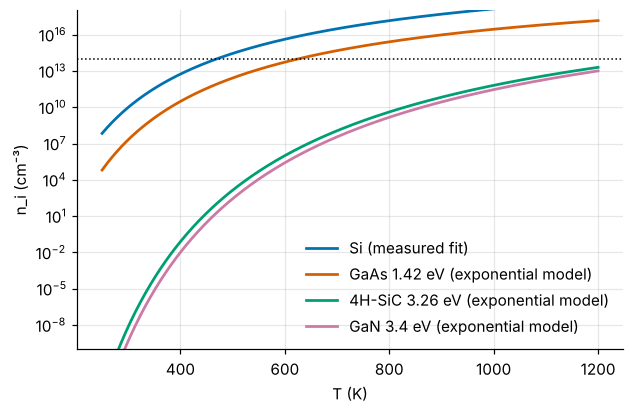

n_i = 1e14 cm^-3 at 469.8 K for Si and 1324 K for 4H-SiC (model)


In [6]:
kB_eV = kB / e
ni_si = lambda T: 5.29e19 * (T / 300)**2.54 * np.exp(-6726 / T)
ni_model = lambda T, Eg: 1.732e19 * (T / 300)**1.5 * np.exp(-Eg / (2 * kB_eV * T))
T = np.linspace(250, 1200, 400)
plt.semilogy(T, ni_si(T), label="Si (measured fit)")
for name, Eg in (("GaAs 1.42 eV", 1.42), ("4H-SiC 3.26 eV", 3.26), ("GaN 3.4 eV", 3.4)):
    plt.semilogy(T, ni_model(T, Eg), label=name + " (exponential model)")
plt.axhline(1e14, color="k", ls=":", lw=1)
plt.ylim(1e-10, 1e18); plt.xlabel("T (K)"); plt.ylabel("n_i (cm⁻³)"); plt.legend(); plt.show()
T_si = brentq(lambda T: ni_si(T) - 1e14, 300, 800)
T_sic = brentq(lambda T: ni_model(T, 3.26) - 1e14, 300, 2000)
print(f"n_i = 1e14 cm^-3 at {T_si:.1f} K for Si and {T_sic:.0f} K for 4H-SiC (model)")

Silicon reaches $10^{14}$ cm⁻³ near 470 K; on the same exponential footing 4H-SiC needs about 1,300 K. Real SiC devices are limited by packaging, contacts and gate oxides long before that, but the semiconductor itself is not the constraint.

## Your turn

1. In Part 1, switch to hard-wall boxes: keep only $n_x, n_y, n_z \ge 1$ and use $E\propto|\vec n|^2/4$ (the wavelengths are $2L/n$). Does the counted Fermi level converge faster or slower, and why?
2. In Part 4, add a second Fourier component $2U_2\cos(4\pi x/a)$ (couple plane waves two apart). Where does the new gap appear, and how wide is it?